# **Mount google drive and point basline to folder where images are**

In [ ]:
# Script: 02_BaselineModel.ipynb
#
# Purpose:
#     Develop and evaluate a baseline convolutional neural network
#     (CNN) for marine organism image classification and compare
#     its classification performance against the pretrained
#     MobileNetV2 transfer learning model.
#
# Input:
#     Marine_Classification/test - 4200 test images
#     Marine_Classification/train - 900 training images
#     Marine_Classification/validation - 900 validation images
#.    Marine_Classification/mobilenetv2_pretrained.keras
# Output:
#    # Output:
#     Marine_Classification/CNN_Baseline/cnn_baseline.keras - Saved baseline CNN model for future use.
#     Marine_Classification/CNN_Baseline/cnn_results.json - Stores training duration, completed epochs, final training and validation metrics, and test accuracy and loss.
#     Marine_Classification/CNN_Baseline/training_history.csv - Records training and validation accuracy and loss for each epoch.
#     Marine_Classification/CNN_Baseline/cnn_classification_report.json - Stores per-class and aggregate classification metrics on the test set.
#     Marine_Classification/CNN_Baseline/cnn_predictions.npz - Stores true labels, predicted labels, class probabilities, and class names.
#     Marine_Classification/CNN_Baseline/class_names.json - Stores the ordered list of marine organism class labels.
#     Marine_Classification/Final_Comparison_Figures/cnn_accuracy.png - Shows baseline CNN training and validation accuracy across epochs.
#     Marine_Classification/Final_Comparison_Figures/cnn_loss.png - Shows baseline CNN training and validation loss across epochs.
#     Marine_Classification/Final_Comparison_Figures/cnn_confusion_matrix.png - Displays the baseline CNN test set confusion matrix.
#     Marine_Classification/Final_Comparison_Figures/organism_precision_comparison.png - Compares test precision across organism categories for both models.
#     Marine_Classification/Final_Comparison_Figures/overall_accuracy_comparison.png - Compares overall test accuracy between MobileNetV2 and the baseline CNN.
#     Marine_Classification/Final_Comparison_Figures/training_accuracy_comparison.png - Compares model training accuracy across epochs.
#     Marine_Classification/Final_Comparison_Figures/test_accuracy_comparison.png - Compares test accuracy between MobileNetV2 and the baseline CNN.
#     Marine_Classification/mobilenet_results.json - Stores test accuracy and test loss for the pretrained MobileNetV2 model.

#     1. Import required Python libraries.
#     2. Connect to Google Drive and define dataset and output paths.
#     3. Load the training, validation, and test image datasets.
#     4. Explore dataset characteristics, including observation
#        availability, image resolutions, heights, and aspect ratios.
#     5. Preprocess images for MobileNetV2.
#     6. Load the pretrained MobileNetV2 model and configure it
#        for marine organism classification.
#     7. Train and evaluate the model using the designated datasets.
#     8. Generate predictions and calculate classification metrics,
#        including accuracy, precision, recall, and F1 scores.
#     9. Generate visualizations, including confusion matrices,
#        precision and recall comparisons, and misclassified images.
#    10. Save the trained model, evaluation results, and figures
#        to the designated Google Drive directories.
#
# Notes:
#     Run this notebook in Google Colab.
#     Connect Google Drive and update the dataset path to point
#     to the copied dataset folder.
#     Use the same dataset splits as the baseline CNN notebook
#     for direct model performance comparison.
#     Run notebook cells in order.





# Mount Google Drive.
from google.colab import drive
drive.mount('/content/drive')

# Import libraries.
import os
import json
import time
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score
)

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Define Google Drive directories.
DRIVE_DIR = "/content/drive/MyDrive/Marine_Classification"

# Dataset location in Colab.
DATA_DIR = "/content/Marine_Dataset"
BASE_DIR ="/content/drive/MyDrive/Marine_Classification"

# CNN model and results directory.
CNN_DIR = os.path.join(DRIVE_DIR, "CNN_Baseline")

# Final figures directory.
OUTPUT_DIR = os.path.join(DRIVE_DIR, "Final_Comparison_Figures")


# Create output directories.
os.makedirs(CNN_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Google Drive setup complete!")

# **Copy images to colab to speed up training!!**

In [ ]:
#NOTE THIS CELL TAKES ~10-15 MINUTES TO COPY -- make sure you have enough space in your temporary colab storage
# Copy only the image datasets from Google Drive to Colab.
for folder in ["train", "validation", "test"]:
    shutil.copytree(
        os.path.join(DRIVE_DIR, folder),
        os.path.join(DATA_DIR, folder),
        dirs_exist_ok=True
    )

print("Copy complete!")

# **Now prepare to create the baseline CNN Model**

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)

# Load training dataset.
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Store class names and number of classes.
class_names = train_ds.class_names
num_classes = len(class_names)

# Load validation dataset.
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "validation"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
    class_names=class_names
)

# Load independent test dataset.
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
    class_names=class_names
)

# Prefetch datasets.
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Number of classes:", num_classes)
print("Classes:", class_names)

# **Load and Resize Images**

In [ ]:
# Import libraries for data handling, model creation, evaluation, and visualization.
import os
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Create a separate folder for saving baseline model results within the google drive folder
BASELINE_DIR = os.path.join(BASE_DIR, "Simple_CNN_Baseline_Results")
os.makedirs(BASELINE_DIR, exist_ok=True)

# Set random seeds to improve reproducibility across runs.
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Define the image dimensions and batch size used in the original model.
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# **Build Basic CNN Architecture**

In [ ]:
# Build a convolutional neural network from scratch.
# Unlike MobileNetV2, this model does not use ImageNet pretrained weights.

cnn_model = models.Sequential([

    # Normalize pixel values from 0–255 to 0–1.
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),

    # First convolutional block: learn basic image features such as edges.
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block: learn more complex patterns and textures.
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block: identify increasingly complex visual features.
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Fourth convolutional block: learn higher-level image representations.
    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Combine spatial features into a single feature vector.
    layers.GlobalAveragePooling2D(),

    # Dropout helps reduce overfitting by randomly excluding neurons during training.
    layers.Dropout(0.3),

    # Output probabilities for each of the 12 marine biodiversity categories.
    layers.Dense(num_classes, activation="softmax")
])

# Configure the model for multiclass classification.
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture and number of trainable parameters.
cnn_model.summary()

# **Train Model**

In [ ]:

# Set the maximum number of training epochs to match the MobileNetV2 experiment.
EPOCHS = 10

# Stop training if validation loss does not improve for 3 consecutive epochs.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Reduce the learning rate if validation loss stops improving.
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# Record the time required to train the model.
start_time = time.time()

# Train the CNN using the training dataset and monitor performance on validation data.
cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr]
)

# Calculate total training time in minutes.
training_time = (time.time() - start_time) / 60

print(f"Total CNN training time: {training_time:.2f} minutes")
print(f"Epochs completed: {len(cnn_history.history['loss'])}")

# **Set up results folder**

# **Save trained model results**

In [ ]:
# Save trained CNN model to Google Drive.
cnn_model.save(
    os.path.join(CNN_DIR, "cnn_baseline.keras")
)

# Save training metrics.
cnn_results = {
    "training_time_minutes": float(training_time),
    "epochs_completed": len(cnn_history.history["loss"]),
    "final_training_accuracy": float(cnn_history.history["accuracy"][-1]),
    "final_validation_accuracy": float(cnn_history.history["val_accuracy"][-1]),
    "final_training_loss": float(cnn_history.history["loss"][-1]),
    "final_validation_loss": float(cnn_history.history["val_loss"][-1])
}

with open(os.path.join(CNN_DIR, "cnn_results.json"), "w") as f:
    json.dump(cnn_results, f, indent=4)

# Save training history.
history_df = pd.DataFrame(cnn_history.history)

history_df.to_csv(
    os.path.join(CNN_DIR, "training_history.csv"),
    index=False
)

print("CNN model and training results saved to Google Drive!")

# **Run on test images and Save Results**

In [ ]:
# Evaluate CNN on the independent test dataset.
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(test_ds)

print("CNN test accuracy:", cnn_test_accuracy)
print("CNN test loss:", cnn_test_loss)

# Add test metrics to results.
cnn_results["test_accuracy"] = float(cnn_test_accuracy)
cnn_results["test_loss"] = float(cnn_test_loss)

# Save updated results.
with open(os.path.join(CNN_DIR, "cnn_results.json"), "w") as f:
    json.dump(cnn_results, f, indent=4)

print("CNN test results saved!")


# **Visualize Training Performance**

In [ ]:
# Plot training and validation accuracy across epochs.
plt.figure(figsize=(8, 5))

plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Simple CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "cnn_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Plot training and validation loss across epochs.
plt.figure(figsize=(8, 5))

plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")

plt.title("Simple CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "cnn_loss.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# **Classification Report**

# **Confusion Matrix**

In [ ]:
# Generate CNN predictions.
y_prob = cnn_model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Extract true labels.
y_true = np.concatenate([y.numpy() for x, y in test_ds])

# Generate classification report.
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Save classification report.
with open(os.path.join(CNN_DIR, "cnn_classification_report.json"), "w") as f:
    json.dump(report, f, indent=4)

# Save predictions for reuse.
np.savez(
    os.path.join(CNN_DIR, "cnn_predictions.npz"),
    y_true=y_true,
    y_pred=y_pred,
    y_prob=y_prob,
    class_names=class_names
)

# Generate confusion matrix.
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=True
)

plt.title("Simple CNN Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "cnn_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Save the trained CNN model to Google Drive.
cnn_model.save(
    os.path.join(CNN_DIR, "cnn_baseline.keras")
)

# Save category names to preserve model output ordering.
with open(os.path.join(CNN_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=4)

# Store final experimental results.
results = {
    "model": "Simple CNN trained from scratch",
    "test_accuracy": float(cnn_test_accuracy),
    "test_loss": float(cnn_test_loss),
    "training_time_minutes": float(training_time),
    "epochs_completed": len(cnn_history.history["loss"]),
    "number_of_classes": num_classes,
    "image_size": "224x224",
    "batch_size": BATCH_SIZE
}

# Save results to Google Drive.
with open(os.path.join(CNN_DIR, "cnn_results.json"), "w") as f:
    json.dump(results, f, indent=4)

print("CNN baseline model and results successfully saved!")

# **COMPARING THE TWO MODELS**

###Load MobileNetV2 Saved Weights

In [ ]:
# Load previously trained models.
mobilenet_model = tf.keras.models.load_model(
    os.path.join(DRIVE_DIR, "mobilenetv2_pretrained.keras")
)

cnn_model = tf.keras.models.load_model(
    os.path.join(CNN_DIR, "cnn_baseline.keras")
)

print("Both models loaded!")

In [ ]:
mobilenet_test_loss, mobilenet_test_accuracy = mobilenet_model.evaluate(test_ds)

print("MobileNetV2 test accuracy:", mobilenet_test_accuracy)
print("MobileNetV2 test loss:", mobilenet_test_loss)

mobilenet_results = {
    "test_accuracy": float(mobilenet_test_accuracy),
    "test_loss": float(mobilenet_test_loss)
}

with open(os.path.join(DRIVE_DIR, "mobilenet_results.json"), "w") as f:
    json.dump(mobilenet_results, f, indent=4)

##Rerun on MobileNetv2 on images with saved weights and save weights

In [ ]:
# Generate predictions from both models.
mobilenet_probs = mobilenet_model.predict(test_ds)
cnn_probs = cnn_model.predict(test_ds)

mobilenet_pred = np.argmax(mobilenet_probs, axis=1)
cnn_pred = np.argmax(cnn_probs, axis=1)

# Calculate per-organism precision.
mobilenet_precision = precision_score(
    y_true, mobilenet_pred, average=None, zero_division=0
)

cnn_precision = precision_score(
    y_true, cnn_pred, average=None, zero_division=0
)

# Convert to percentages.
mobilenet_precision *= 100
cnn_precision *= 100

# Create grouped bar chart.
x = np.arange(len(class_names))
width = 0.38

plt.figure(figsize=(14, 6))

plt.bar(
    x - width/2,
    mobilenet_precision,
    width,
    label="MobileNetV2"
)

plt.bar(
    x + width/2,
    cnn_precision,
    width,
    label="CNN Baseline"
)

plt.xlabel("Marine Organism")
plt.ylabel("Precision (%)")
plt.title("Per-Class Precision: MobileNetV2 vs. CNN Baseline")
plt.xticks(x, class_names, rotation=45, ha="right")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "organism_precision_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Create per organism precision plot compared across models**

In [ ]:
# Evaluate MobileNetV2
mobilenet_test_loss, mobilenet_test_accuracy = mobilenet_model.evaluate(test_ds)

# Get CNN accuracy from saved results
with open(os.path.join(CNN_DIR, "cnn_results.json"), "r") as f:
    cnn_results = json.load(f)

cnn_test_accuracy = cnn_results["test_accuracy"]

29/29 ━━━━━━━━━━━━━━━━━━━━ 9s 53ms/step - accuracy: 0.8144 - loss: 0.5675


# **Accuracy comparison between models**

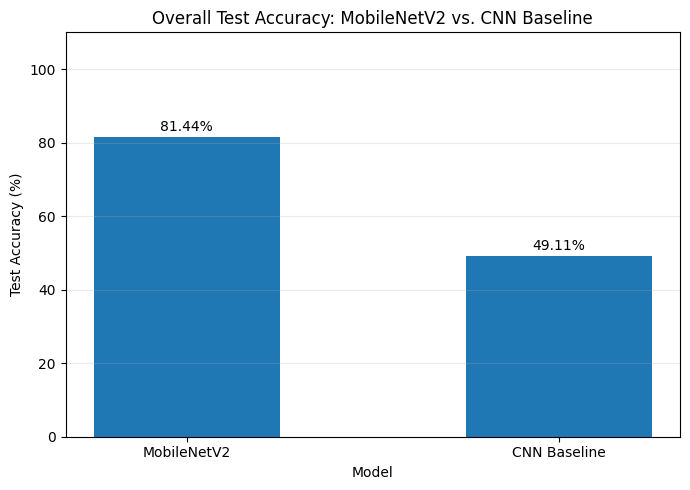

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Store test accuracy for both models as percentages.
model_names = ["MobileNetV2", "CNN Baseline"]

accuracies = [
    mobilenet_test_accuracy * 100,
    cnn_test_accuracy * 100
]

# Create bar chart.
plt.figure(figsize=(7, 5))

bars = plt.bar(
    model_names,
    accuracies,
    width=0.5
)

# Display accuracy values above each bar.
for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom"
    )

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("Overall Test Accuracy: MobileNetV2 vs. CNN Baseline")
plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

# Save figure to Google Drive.
plt.savefig(
    os.path.join(BASE_DIR, "overall_accuracy_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()